# Lorenz Dynamics and Autoregression

Simulate the Lorenz system with fourth-order Runge-Kutta integration. Compare held-out one-step prediction across AR orders, then use a two-regime threshold AR model to simulate a trajectory and inspect its delay geometry.


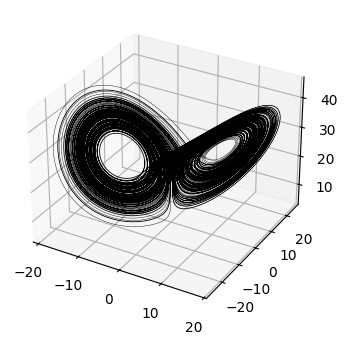

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import neuralfieldmanifold as nfm

trajectory = nfm.simulation.lorenz(40000, dt=.005)
x = trajectory[:, 0]
fig = plt.figure(figsize=(5, 4))
ax = fig.add_subplot(111, projection='3d')
ax.plot(*trajectory[2000:].T, color='black', lw=.3)
plt.show()


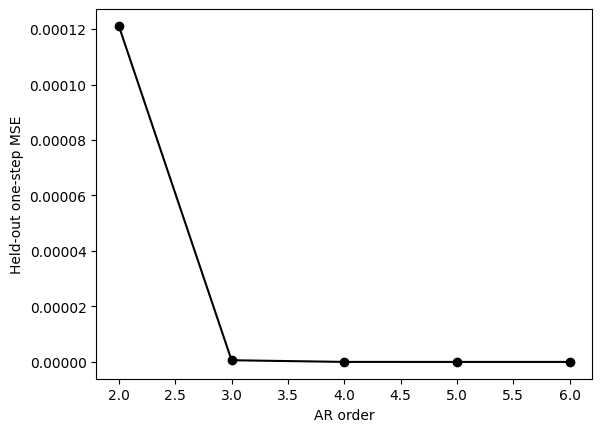

In [2]:
orders = np.arange(2, 7)
errors = []
for order in orders:
    n_train = int(.8 * (len(x) - order))
    fit = nfm.models.AR(order=int(order)).fit(x[:n_train + order])
    predicted = fit.predict(x)[n_train:]
    errors.append(nfm.models.prediction_metrics(x[n_train + order:], predicted).mse)
plt.plot(orders, errors, 'o-', color='black')
plt.xlabel('AR order')
plt.ylabel('Held-out one-step MSE')
plt.show()


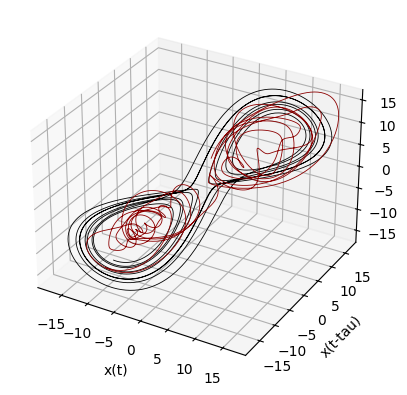

In [3]:
x = nfm.simulation.lorenz(12000)[:, 0]
order = 8
n_train = int(.8 * (len(x) - order))
fit = nfm.models.TAR(order=order, delay_samples=1, threshold=0).fit(x[:n_train + order])
start = n_train + order
observed = x[start:]
initial = np.array([x[start - i] for i in range(1, order + 1)])
simulated = fit.simulate(initial, n_samples=len(observed), seed=42, match_reference=observed)
cloud = nfm.embedding.delay(observed.astype(np.float32), dimension=3, tau_samples=15)
model_cloud = nfm.embedding.delay(simulated.astype(np.float32), dimension=3, tau_samples=15)
ax = nfm.plotting.embedding(cloud)
nfm.plotting.embedding(model_cloud, ax=ax, color='darkred')
plt.show()


## Compare Delay Geometry

The threshold AR simulation is matched to the observed test segment's mean and standard deviation before plotting. This comparison concerns trajectory shape; it is separate from the held-out one-step prediction errors above.
